In [ ]:
import numpy as np


def load_asc(filename: str) -> np.ndarray:
    rows = []
    with open(filename, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                if rows:
                    break
                continue
            parts = line.split(",")
            try:
                rows.append((float(parts[0]), sum(float(x) for x in parts[1:] if x.strip()) / (len(parts) - 1)))
            except (ValueError, IndexError):
                if rows:
                    break
                continue
    rows = np.array(rows)
    # Wavelength unify to 1 decimal place
    rows[:, 0] = np.round(rows[:, 0], 1)
    return rows


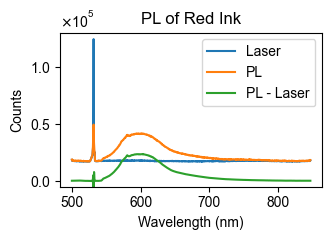

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

plt.rcParams.update({"font.size": 10, "font.family": "Arial"})

fmt = ScalarFormatter(useMathText=True)
fmt.set_powerlimits((0, 0))

pl_data = load_asc("assets/data/ink/redink_1010_01.asc")
laser_data = load_asc("assets/data/ink/laser_1010.asc")

pl_signal = pl_data[:, 1] - laser_data[:, 1]
wavelength = pl_data[:, 0]

fig, ax = plt.subplots(figsize=(3.5, 2.5))
ax.plot(wavelength, laser_data[:, 1], label="Laser")
ax.plot(wavelength, pl_data[:, 1], label="PL")
ax.plot(wavelength, pl_signal, label="PL - Laser")
ax.legend()
ax.set_ylim(-5000, 130000)
ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Counts")
ax.set_title("PL of Red Ink")
fig.tight_layout()
fig.savefig("assets/data/ink/redink_pl.png", dpi=600, bbox_inches="tight")

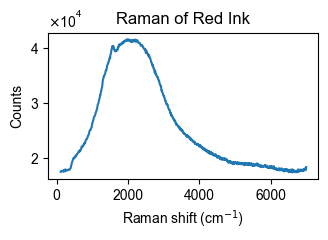

In [22]:
lambda_ex = 532  # nm, laser excitation (measured peak at ~531.6 nm)

# Raman shift (cm^-1) = 1e7 * (1/lambda_ex - 1/lambda), keep Stokes side only
mask = wavelength > lambda_ex + 3  # skip the Rayleigh line
raman_shift = 1e7 * (1 / lambda_ex - 1 / wavelength[mask])

fig, ax = plt.subplots(figsize=(3.5, 2.5))
ax.plot(raman_shift, pl_data[mask, 1])
ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_ylabel("Counts")
ax.set_title("Raman of Red Ink")
fig.tight_layout()
fig.savefig("assets/data/ink/redink_raman.png", dpi=600, bbox_inches="tight")


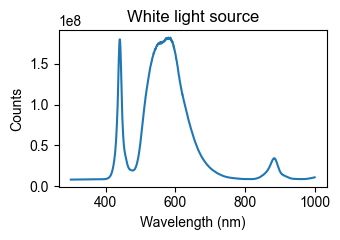

In [38]:
whitelight_wide = load_asc("assets/data/ink/whitelight_10xBF_300to1000nm.asc")
whitelight = load_asc("assets/data/ink/whitelight_BF10x.asc")

fig, ax = plt.subplots(figsize=(3.5, 2.5))
ax.plot(whitelight_wide[:, 0], whitelight_wide[:, 1] / 5e-5)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Counts")
ax.set_title("White light source")
fig.tight_layout()
fig.savefig("assets/data/ink/whitelight.png", dpi=600, bbox_inches="tight")